### Nama : M. Padil Mangulele
### Nim :  H061241071
# Modul: Merancang Prompt AI yang Terukur untuk Analisis Geofisika
## Framework R–T–C–I–K–O–Q–V dengan Studi Kasus Seismik Refraksi

## 1. Pendahuluan

Dalam geofisika, hasil interpretasi harus bisa **ditelusuri** dan **diuji ulang**. Prompt AI yang asal-asalan menghasilkan jawaban yang terdengar meyakinkan tetapi sulit diaudit. Karena itu prompt sebaiknya diperlakukan sebagai **spesifikasi kerja**, bukan sekadar pertanyaan.

Framework **R–T–C–I–K–O–Q–V** membagi prompt menjadi dua kelompok:

- **Spesifikasi pekerjaan**: R (Role), T (Task), C (Context), I (Input), K (Constraints)
- **Deliverable dan penerimaan**: O (Output), Q (Quality criteria), V (Verification, opsional)

Pada modul ini kita tidak hanya membaca teori, tetapi juga membandingkan prompt buruk dan baik, lalu menguji kelengkapan prompt dengan kode Python.

## 2. Diagram Alur Framework

Diagram digambar langsung dengan `matplotlib`, jadi tidak perlu berkas gambar terpisah.

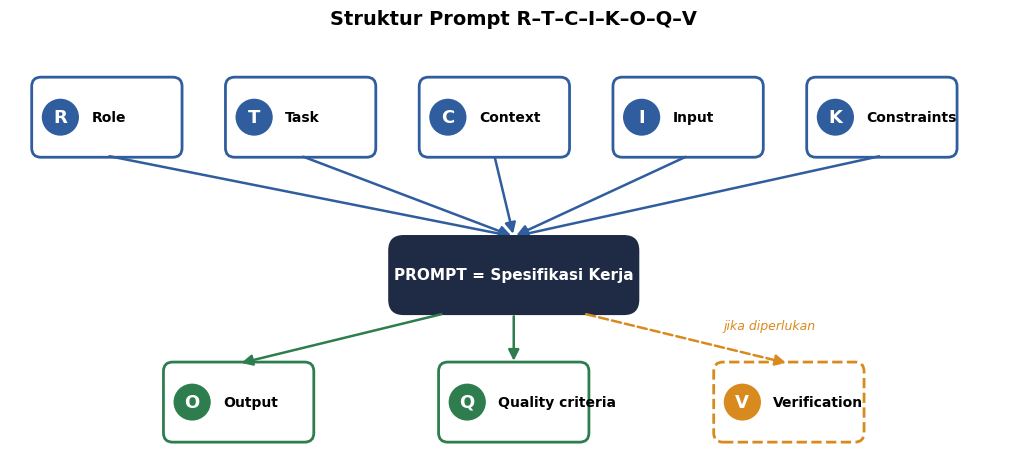

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle

def gambar_framework():
    fig, ax = plt.subplots(figsize=(13, 5.5))
    ax.set_xlim(0, 13); ax.set_ylim(0, 5.5); ax.axis("off")

    def kotak(x, y, huruf, judul, warna, putus=False):
        ax.add_patch(FancyBboxPatch((x, y), 1.9, 1.0, boxstyle="round,pad=0.02,rounding_size=0.12",
                     fc="white", ec=warna, lw=2, ls="--" if putus else "-"))
        ax.add_patch(Circle((x+0.35, y+0.5), 0.24, fc=warna, ec="none"))
        ax.text(x+0.35, y+0.5, huruf, ha="center", va="center", color="white", fontsize=13, fontweight="bold")
        ax.text(x+0.75, y+0.5, judul, ha="left", va="center", fontsize=10, fontweight="bold")

    def panah(a, b, warna="#555", putus=False):
        ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=16, lw=1.8,
                     color=warna, ls="--" if putus else "-"))

    biru, hijau, oranye = "#2F5D9E", "#2E7D4F", "#D98A1F"
    # Baris spesifikasi
    for i, (h, j) in enumerate([("R","Role"),("T","Task"),("C","Context"),("I","Input"),("K","Constraints")]):
        kotak(0.3 + i*2.5, 3.9, h, j, biru)
        panah((1.25 + i*2.5, 3.9), (6.5, 2.85), biru)

    # Pusat
    ax.add_patch(FancyBboxPatch((4.9, 1.85), 3.2, 1.0, boxstyle="round,pad=0.02,rounding_size=0.2",
                 fc="#1F2A44", ec="none"))
    ax.text(6.5, 2.35, "PROMPT = Spesifikasi Kerja", ha="center", va="center", color="white", fontsize=11, fontweight="bold")

    # Baris deliverable
    kotak(2.0, 0.2, "O", "Output", hijau)
    kotak(5.55, 0.2, "Q", "Quality criteria", hijau)
    kotak(9.1, 0.2, "V", "Verification", oranye, putus=True)
    panah((5.6, 1.85), (2.95, 1.2), hijau)
    panah((6.5, 1.85), (6.5, 1.2), hijau)
    panah((7.4, 1.85), (10.05, 1.2), oranye, putus=True)
    ax.text(9.2, 1.65, "jika diperlukan", fontsize=9, style="italic", color=oranye)

    ax.set_title("Struktur Prompt R–T–C–I–K–O–Q–V", fontsize=14, fontweight="bold")
    plt.show()

gambar_framework()

## 3. Penjelasan Komponen

| Komponen | Pertanyaan yang dijawab | Contoh dalam geofisika |
|---|---|---|
| **R** – Role | Siapa yang mengerjakan? | "Geofisikawan teknik sipil berpengalaman seismik refraksi" |
| **T** – Task | Apa yang dikerjakan? | "Tentukan kecepatan dan ketebalan tiap lapisan" |
| **C** – Context | Dalam situasi apa? | Lokasi, tujuan survei, geometri, kondisi geologi |
| **I** – Input | Data apa yang tersedia? | Tabel waktu tiba (t) vs jarak (x), satuan, jumlah geophone |
| **K** – Constraints | Apa yang boleh dan tidak boleh? | "Tidak boleh mengarang data", "tampilkan rumus" |
| **O** – Output | Bentuk hasilnya seperti apa? | Tabel parameter, grafik, ringkasan |
| **Q** – Quality criteria | Kapan hasil dinilai layak? | Semua angka dapat ditelusuri, satuan konsisten |
| **V** – Verification | Bagaimana hasil diuji? | Hitung ulang, bandingkan dengan data bor, uji sensitivitas |

## 4. Perbandingan: Prompt Buruk vs Prompt Baik

Kasus: **seismik refraksi** untuk menentukan kedalaman batuan dasar (*bedrock*) di lokasi calon fondasi bangunan.

### 4.1 Prompt buruk

In [2]:
prompt_buruk = "Tolong analisis data seismik refraksi saya dan cari kedalaman batuan dasar."
print(prompt_buruk)

Tolong analisis data seismik refraksi saya dan cari kedalaman batuan dasar.


Masalahnya:
- Tidak ada peran, sehingga level jawaban tidak jelas.
- Data tidak dilampirkan atau dijelaskan, sehingga AI cenderung **mengarang angka**.
- Tidak ada batasan metode, sehingga AI bebas memilih rumus sendiri.
- Tidak ada format keluaran dan kriteria penerimaan, sehingga hasilnya tidak bisa dinilai.

### 4.2 Prompt baik

In [3]:
prompt_baik = """
### Role
Anda adalah geofisikawan teknik sipil yang berpengalaman dalam akuisisi dan
interpretasi seismik refraksi dua lapis.

### Task
Tentukan kecepatan gelombang P lapisan atas (V1), kecepatan lapisan bawah (V2),
jarak silang (crossover distance), dan kedalaman batuan dasar dari data
first-arrival berikut.

### Context
Survei dilakukan untuk calon fondasi gedung dua lantai pada satu lintasan
lurus sepanjang 44 m dengan 12 geophone berspasi 4 m. Sumber pukulan palu
di ujung lintasan (forward shot). Diduga terdapat tanah lapuk di atas batuan dasar.

### Input
Tabel waktu tiba gelombang P pertama (jarak dalam meter, waktu dalam milidetik):
x = [0, 4, 8, 12, 16, 20, 24, 28, 32, 36, 40, 44]
t = [0, 8, 16, 24, 29, 33, 37, 41, 45, 49, 53, 57]

### Constraints
- Gunakan hanya data pada bagian Input; dilarang menambah atau mengubah titik data.
- Gunakan model dua lapis horizontal dan metode jarak silang atau intercept time.
- Tampilkan rumus dan langkah hitung, lengkap dengan satuan (m/s, m, ms).
- Jika data tidak mendukung suatu kesimpulan, tulis "tidak dapat ditentukan".

### Output
1. Tabel: V1, V2, jarak silang, kedalaman batuan dasar
2. Grafik jarak vs waktu tiba beserta garis fit tiap segmen
3. Interpretasi singkat (maksimal 5 kalimat)

### Quality Criteria
- Semua angka pada interpretasi dapat ditelusuri ke perhitungan.
- Satuan konsisten di seluruh laporan.
- Ketidakpastian atau keterbatasan model disebutkan.

### Optional Verification
Hitung ulang kedalaman dengan metode intercept time dan bandingkan hasilnya
dengan metode jarak silang.
"""
print(prompt_baik)


### Role
Anda adalah geofisikawan teknik sipil yang berpengalaman dalam akuisisi dan
interpretasi seismik refraksi dua lapis.

### Task
Tentukan kecepatan gelombang P lapisan atas (V1), kecepatan lapisan bawah (V2),
jarak silang (crossover distance), dan kedalaman batuan dasar dari data
first-arrival berikut.

### Context
Survei dilakukan untuk calon fondasi gedung dua lantai pada satu lintasan
lurus sepanjang 44 m dengan 12 geophone berspasi 4 m. Sumber pukulan palu
di ujung lintasan (forward shot). Diduga terdapat tanah lapuk di atas batuan dasar.

### Input
Tabel waktu tiba gelombang P pertama (jarak dalam meter, waktu dalam milidetik):
x = [0, 4, 8, 12, 16, 20, 24, 28, 32, 36, 40, 44]
t = [0, 8, 16, 24, 29, 33, 37, 41, 45, 49, 53, 57]

### Constraints
- Gunakan hanya data pada bagian Input; dilarang menambah atau mengubah titik data.
- Gunakan model dua lapis horizontal dan metode jarak silang atau intercept time.
- Tampilkan rumus dan langkah hitung, lengkap dengan satuan (m/s, m

## 5. Membuktikan Isi Prompt: Menghitung Sendiri Jawabannya

Karena prompt di atas memuat data lengkap, kita bisa **menghitung sendiri** hasilnya sebagai pembanding jawaban AI. Ini contoh komponen **V (Verification)** yang sesungguhnya.

V1 (lapisan atas)      :    500.0 m/s
V2 (lapisan bawah)     :   1000.0 m/s
Intercept time         :    13.00 ms
Jarak silang           :    13.00 m
Kedalaman (intercept)  :     3.75 m
Kedalaman (crossover)  :     3.75 m


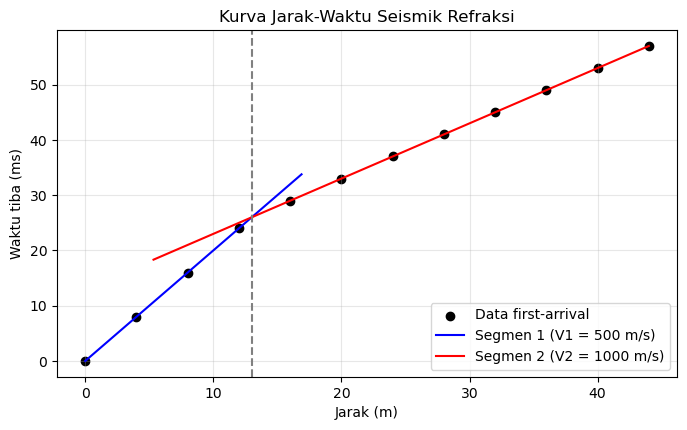

In [3]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([0, 4, 8, 12, 16, 20, 24, 28, 32, 36, 40, 44], dtype=float)  # m
t = np.array([0, 8, 16, 24, 29, 33, 37, 41, 45, 49, 53, 57], dtype=float) / 1000  # s

# Segmen 1 (gelombang langsung): titik 0-12 m; Segmen 2 (bias): titik 16-44 m
p1 = np.polyfit(x[:4], t[:4], 1)
p2 = np.polyfit(x[4:], t[4:], 1)

V1 = 1 / p1[0]              # m/s
V2 = 1 / p2[0]              # m/s
Ti = p2[1]                  # intercept time (s)
xc = (p2[1] - p1[1]) / (p1[0] - p2[0])                       # jarak silang (m)
z_intercept = Ti * V1 * V2 / (2 * np.sqrt(V2**2 - V1**2))    # m
z_crossover = (xc / 2) * np.sqrt((V2 - V1) / (V2 + V1))      # m

print(f"V1 (lapisan atas)      : {V1:8.1f} m/s")
print(f"V2 (lapisan bawah)     : {V2:8.1f} m/s")
print(f"Intercept time         : {Ti*1000:8.2f} ms")
print(f"Jarak silang           : {xc:8.2f} m")
print(f"Kedalaman (intercept)  : {z_intercept:8.2f} m")
print(f"Kedalaman (crossover)  : {z_crossover:8.2f} m")

plt.figure(figsize=(8, 4.5))
plt.scatter(x, t*1000, c="k", label="Data first-arrival")
xx = np.linspace(0, 44, 100)
plt.plot(xx[xx <= xc+4], np.polyval(p1, xx[xx <= xc+4])*1000, "b-", label=f"Segmen 1 (V1 = {V1:.0f} m/s)")
plt.plot(xx[xx >= xc-8], np.polyval(p2, xx[xx >= xc-8])*1000, "r-", label=f"Segmen 2 (V2 = {V2:.0f} m/s)")
plt.axvline(xc, ls="--", c="gray")
plt.xlabel("Jarak (m)"); plt.ylabel("Waktu tiba (ms)")
plt.title("Kurva Jarak-Waktu Seismik Refraksi"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

> **Catatan:** data pada contoh ini adalah **data ilustrasi** yang dibuat untuk keperluan modul, bukan data lapangan. Nilai yang keluar hanya berfungsi sebagai pembanding jawaban AI.

## 6. Pengecek Kelengkapan Prompt Otomatis

Fungsi sederhana berikut memeriksa apakah sebuah prompt memuat kedelapan komponen framework.

In [4]:
import re

KOMPONEN = {
    "R": ["role", "peran", "bertindak sebagai", "anda adalah"],
    "T": ["task", "tugas"],
    "C": ["context", "konteks", "latar belakang"],
    "I": ["input", "data"],
    "K": ["constraint", "batasan", "dilarang", "tidak boleh"],
    "O": ["output", "keluaran", "format"],
    "Q": ["quality", "kriteria"],
    "V": ["verification", "verifikasi"],
}

def cek_prompt(teks):
    teks_kecil = teks.lower()
    hasil = {}
    for kode, kata_kunci in KOMPONEN.items():
        hasil[kode] = any(re.search(re.escape(k), teks_kecil) for k in kata_kunci)
    wajib = ["R", "T", "C", "I", "K", "O", "Q"]      # V bersifat opsional
    skor = sum(hasil[k] for k in wajib)
    print(f"Skor komponen wajib: {skor}/{len(wajib)}")
    for kode, ada in hasil.items():
        tanda = "ada" if ada else "TIDAK ADA"
        opsional = " (opsional)" if kode == "V" else ""
        print(f"  [{kode}] {tanda}{opsional}")
    kurang = [k for k in wajib if not hasil[k]]
    print("Kesimpulan:", "prompt lengkap" if not kurang else f"lengkapi komponen {', '.join(kurang)}")

print("=== Prompt buruk ===")
cek_prompt(prompt_buruk)
print()
print("=== Prompt baik ===")
cek_prompt(prompt_baik)

=== Prompt buruk ===
Skor komponen wajib: 1/7
  [R] TIDAK ADA
  [T] TIDAK ADA
  [C] TIDAK ADA
  [I] ada
  [K] TIDAK ADA
  [O] TIDAK ADA
  [Q] TIDAK ADA
  [V] TIDAK ADA (opsional)
Kesimpulan: lengkapi komponen R, T, C, K, O, Q

=== Prompt baik ===


NameError: name 'prompt_baik' is not defined

Pengecek ini hanya memeriksa **keberadaan** kata kunci, bukan **mutu** isinya. Prompt yang lolos pengecek belum tentu prompt yang baik, jadi penilaian akhir tetap dilakukan manusia.

## 7. Template Kosong

In [5]:
template = """
### Role
[Peran dan tingkat keahlian yang diminta]

### Task
[Tugas dengan kata kerja aksi yang terukur]

### Context
[Lokasi, metode survei, tujuan studi, kondisi geologi]

### Input
[Data yang tersedia beserta format dan satuannya]

### Constraints
[Metode wajib, asumsi yang diizinkan, larangan mengarang data]

### Output
[Bentuk keluaran: tabel, grafik, laporan]

### Quality Criteria
[Syarat agar hasil dapat diterima]

### Optional Verification
[Cara menguji hasil, bila relevan]
"""
print(template)


### Role
[Peran dan tingkat keahlian yang diminta]

### Task
[Tugas dengan kata kerja aksi yang terukur]

### Context
[Lokasi, metode survei, tujuan studi, kondisi geologi]

### Input
[Data yang tersedia beserta format dan satuannya]

### Constraints
[Metode wajib, asumsi yang diizinkan, larangan mengarang data]

### Output
[Bentuk keluaran: tabel, grafik, laporan]

### Quality Criteria
[Syarat agar hasil dapat diterima]

### Optional Verification
[Cara menguji hasil, bila relevan]



## 8. Latihan

Kerjakan pada sel kode di bawahnya:

1. Pilih satu metode geofisika lain (gravitasi, magnetik, geolistrik, atau GPR).
2. Tulis prompt lengkap dengan template di atas, termasuk data contoh yang kecil.
3. Uji dengan `cek_prompt()` dan perbaiki sampai semua komponen wajib terpenuhi.
4. Jelaskan dalam 3 sampai 5 kalimat mengapa bagian **Constraints** pada prompt Anda penting.

In [6]:
prompt_saya = """
### Role
...
"""
# cek_prompt(prompt_saya)

## 9. Catatan Penutup

- Prompt yang baik adalah **kontrak kerja**: jelas apa yang diminta, apa batasannya, dan bagaimana hasilnya dinilai.
- Detail boleh diringkas bila sudah tersimpan dalam template atau konfigurasi proyek, tetapi **Constraints** dan **Quality Criteria** tidak boleh hilang.
- Selalu sediakan cara memverifikasi hasil AI, misalnya dengan perhitungan mandiri seperti pada bagian 5.